In [10]:
from google.colab import files

arquivos = files.upload()

Saving Online Retail.xlsx to Online Retail (1).xlsx


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

print("Ambiente pronto!")

Ambiente pronto!


In [1]:
print("Teste do projeto")
print("A variável df existe?", "df" in globals())

Teste do projeto
A variável df existe? False


In [9]:
df = pd.read_excel("Online Retail.xlsx")

In [ ]:
# 1. Verificar valores ausentes
print("Valores ausentes por coluna:")
print(df.isnull().sum())

# 2. Verificar linhas duplicadas
print("\nLinhas duplicadas:", df.duplicated().sum())

# 3. Verificar estatísticas de quantidade e preço
print("\nResumo estatístico:")
display(df[["Quantity", "UnitPrice"]].describe())

Valores ausentes por coluna:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country            0
dtype: int64

Linhas duplicadas: 5268

Resumo estatístico:


,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


In [ ]:
# Calcular o faturamento de cada linha
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

# Mostrar os principais indicadores
print("Total de registros:", len(df))
print("Quantidade total:", df["Quantity"].sum())
print("Faturamento total: £", round(df["Revenue"].sum(), 2))
print("Países diferentes:", df["Country"].nunique())
print("Produtos diferentes:", df["Description"].nunique())

Total de registros: 541909
Quantidade total: 5176450
Faturamento total: £ 9747747.93
Países diferentes: 38
Produtos diferentes: 4223


,Country,Revenue
0,United Kingdom,8187806.364
1,Netherlands,284661.540
2,EIRE,263276.820
3,Germany,221698.210
4,France,197403.900
5,Australia,137077.270
6,Switzerland,56385.350
7,Spain,54774.580
8,Belgium,40910.960
9,Sweden,36595.910


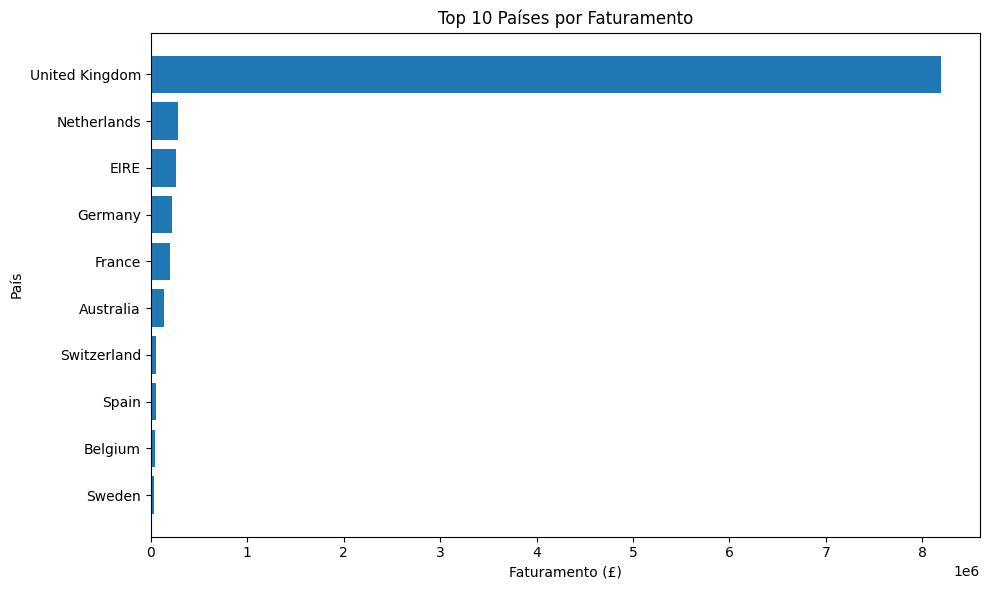

In [ ]:
# Somar o faturamento por país
faturamento_pais = (
    df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Mostrar os 10 países com maior faturamento
display(faturamento_pais.head(10).reset_index())

# Criar gráfico dos 10 países com maior faturamento
import matplotlib.pyplot as plt

top_paises = faturamento_pais.head(10).sort_values()

plt.figure(figsize=(10, 6))
plt.barh(top_paises.index, top_paises.values)
plt.title("Top 10 Países por Faturamento")
plt.xlabel("Faturamento (£)")
plt.ylabel("País")
plt.tight_layout()
plt.show()

Top 10 produtos por Faturamento:


,Description,Revenue
0,DOTCOM POSTAGE,206245.48
1,REGENCY CAKESTAND 3 TIER,164762.19
2,WHITE HANGING HEART T-LIGHT HOLDER,99668.47
3,PARTY BUNTING,98302.98
4,JUMBO BAG RED RETROSPOT,92356.03
5,RABBIT NIGHT LIGHT,66756.59
6,POSTAGE,66230.64
7,PAPER CHAIN KIT 50'S CHRISTMAS,63791.94
8,ASSORTED COLOUR BIRD ORNAMENT,58959.73
9,CHILLI LIGHTS,53768.06


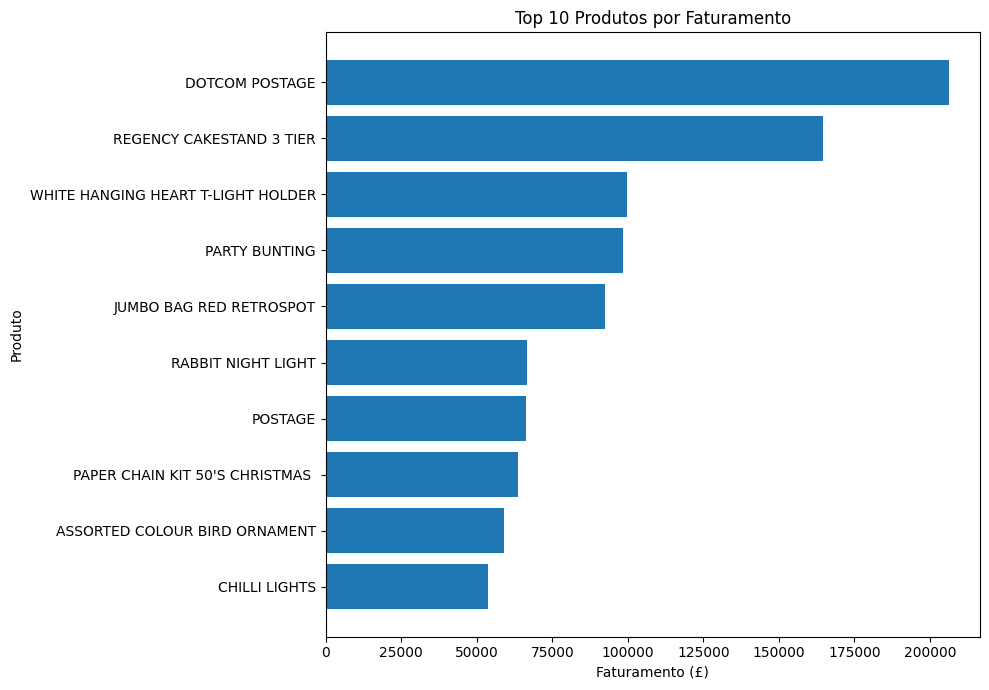

In [ ]:
# Selecionar os 10 produtos com maior faturamento
faturamento_produtos = (
    df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 produtos por faturamento:")
display(faturamento_produtos.head(10).reset_index())

# Criar gráfico
top_produtos = faturamento_produtos.head(10).sort_values()

plt.figure(figsize=(10, 7))
plt.barh(top_produtos.index, top_produtos.values)
plt.title("Top 10 Produtos por Faturamento")
plt.xlabel("Faturamento (£)")
plt.ylabel("Produto")
plt.tight_layout()
plt.show()

,Month,Revenue
0,2010-12,748957.020
1,2011-01,560000.260
2,2011-02,498062.650
3,2011-03,683267.080
4,2011-04,493207.121
5,2011-05,723333.510
6,2011-06,691123.120
7,2011-07,681300.111
8,2011-08,682680.510
9,2011-09,1019687.622


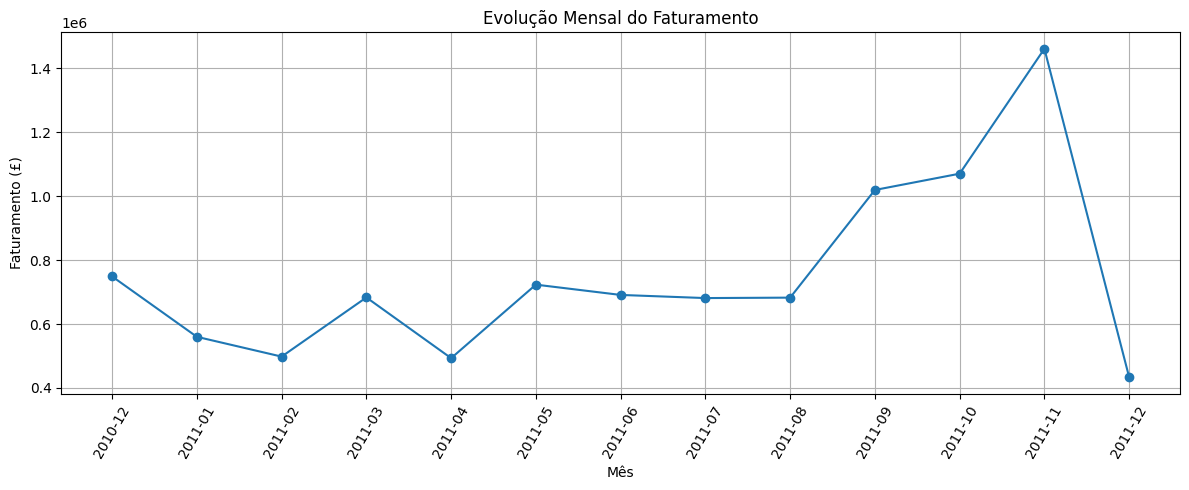

In [ ]:
# Converter a data para o formato correto
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Criar uma coluna com o mês e o ano
df["Month"] = df["InvoiceDate"].dt.to_period("M").astype(str)

# Somar o faturamento por mês
faturamento_mensal = (
    df.groupby("Month")["Revenue"]
    .sum()
    .sort_index()
)

# Mostrar os resultados
display(faturamento_mensal.reset_index())

# Criar gráfico da evolução mensal
plt.figure(figsize=(12, 5))
plt.plot(
    faturamento_mensal.index,
    faturamento_mensal.values,
    marker="o"
)
plt.title("Evolução Mensal do Faturamento")
plt.xlabel("Mês")
plt.ylabel("Faturamento (£)")
plt.xticks(rotation=60)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Preparar os dados mensais para a previsão
from sklearn.linear_model import LinearRegression
import numpy as np
import pandas as pd

dados_mensais = faturamento_mensal.reset_index()
dados_mensais.columns = ["Month", "Revenue"]

# Criar uma sequência numérica para representar os meses
dados_mensais["Month_Number"] = np.arange(len(dados_mensais))

# Treinar um modelo simples de regressão linear
X = dados_mensais[["Month_Number"]]
y = dados_mensais["Revenue"]

modelo = LinearRegression()
modelo.fit(X, y)

# Prever o faturamento do próximo mês
proximo_mes_numero = len(dados_mensais)
previsao = modelo.predict(pd.DataFrame({
    "Month_Number": [proximo_mes_numero]
}))[0]

print("Último mês da base:", dados_mensais["Month"].iloc[-1])
print("Previsão para o próximo mês: £", round(previsao, 2))

Último mês da base: 2011-12
Previsão para o próximo mês: £ 990357.11


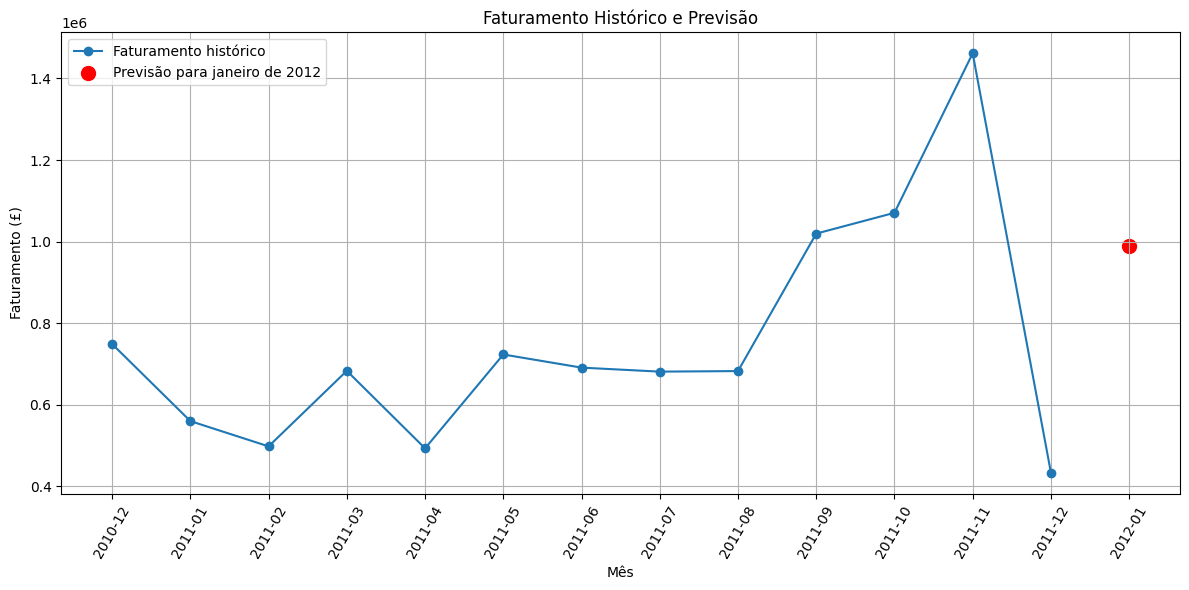

In [ ]:
# Visualizar o histórico e a previsão
plt.figure(figsize=(12, 6))

plt.plot(
    dados_mensais["Month"],
    dados_mensais["Revenue"],
    marker="o",
    label="Faturamento histórico"
)

plt.scatter(
    ["2012-01"],
    [previsao],
    color="red",
    s=100,
    label="Previsão para janeiro de 2012"
)

plt.title("Faturamento Histórico e Previsão")
plt.xlabel("Mês")
plt.ylabel("Faturamento (£)")
plt.xticks(rotation=60)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Resumo dos resultados da análise

pais_lider = faturamento_pais.idxmax()
valor_pais_lider = faturamento_pais.max()

produto_lider = faturamento_produtos.idxmax()
valor_produto_lider = faturamento_produtos.max()

mes_maior_faturamento = faturamento_mensal.idxmax()
valor_mes_maior = faturamento_mensal.max()

print("===== RESUMO DA ANÁLISE =====")
print(f"Registros analisados: {len(df):,}")
print(f"Países presentes: {df['Country'].nunique()}")
print(f"Faturamento líquido calculado: £ {df['Revenue'].sum():,.2f}")
print(f"País com maior faturamento: {pais_lider}")
print(f"Faturamento desse país: £ {valor_pais_lider:,.2f}")
print(f"Produto com maior faturamento: {produto_lider}")
print(f"Faturamento desse produto: £ {valor_produto_lider:,.2f}")
print(f"Mês com maior faturamento: {mes_maior_faturamento}")
print(f"Faturamento desse mês: £ {valor_mes_maior:,.2f}")
print(f"Previsão para janeiro de 2012: £ {previsao:,.2f}")

===== RESUMO DA ANÁLISE =====
Registros analisados: 541,909
Países presentes: 38
Faturamento líquido calculado: £ 9,747,747.93
País com maior faturamento: United Kingdom
Faturamento desse país: £ 8,187,806.36
Produto com maior faturamento: DOTCOM POSTAGE
Faturamento desse produto: £ 206,245.48
Mês com maior faturamento: 2011-11
Faturamento desse mês: £ 1,461,756.25
Previsão para janeiro de 2012: £ 990,357.11


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Separar os meses: treinar com os primeiros 80% e testar nos restantes
dados_teste = dados_mensais.copy()
corte = int(len(dados_teste) * 0.8)

treino = dados_teste.iloc[:corte]
teste = dados_teste.iloc[corte:]

X_treino = treino[["Month_Number"]]
y_treino = treino["Revenue"]

X_teste = teste[["Month_Number"]]
y_teste = teste["Revenue"]

# Treinar e avaliar o modelo
modelo_teste = LinearRegression()
modelo_teste.fit(X_treino, y_treino)

previsoes_teste = modelo_teste.predict(X_teste)

mae = mean_absolute_error(y_teste, previsoes_teste)
rmse = np.sqrt(mean_squared_error(y_teste, previsoes_teste))

print("Meses usados no treinamento:", len(treino))
print("Meses usados no teste:", len(teste))
print(f"Erro absoluto médio (MAE): £ {mae:,.2f}")
print(f"Raiz do erro quadrático médio (RMSE): £ {rmse:,.2f}")

Meses usados no treinamento: 10
Meses usados no teste: 3
Erro absoluto médio (MAE): £ 432,950.77
Raiz do erro quadrático médio (RMSE): £ 457,856.98


### Conclusão — Análise Preditiva de Vendas

O projeto teve como objetivo analisar uma base de dados de vendas utilizando Python e bibliotecas voltadas à Ciência de Dados, como Pandas, Matplotlib e Scikit-learn. A base utilizada contém 541.909 registros, distribuídos por 38 países, permitindo explorar informações sobre quantidades, preços, faturamento e períodos de venda.

Durante a análise, foi calculado um faturamento líquido de £ 9.747.747,93, considerando os valores positivos e negativos presentes nos registros. O Reino Unido apresentou o maior faturamento entre os países, com £ 8.187.806,36. Novembro de 2011 foi o mês com maior faturamento registrado, totalizando £ 1.461.756,25. A descrição “DOTCOM POSTAGE” apresentou o maior valor acumulado na análise por descrição, sendo necessário considerar que se refere a postagem, e não necessariamente a um produto comercial convencional.

Na etapa preditiva, foi aplicada uma regressão linear simples aos dados mensais, gerando uma estimativa de £ 990.357,11 para janeiro de 2012. Esse resultado deve ser interpretado com cautela, pois o modelo utiliza uma abordagem básica e não considera explicitamente fatores como sazonalidade, devoluções ou outras variações no comportamento das vendas.

Conclui-se que o projeto permitiu praticar a importação, organização, exploração e visualização de dados, além da aplicação inicial de um modelo de previsão. Como melhoria futura, seria importante tratar os registros negativos e duplicados, avaliar a qualidade das previsões com dados separados para teste e comparar diferentes modelos para verificar qual apresenta melhores resultados.

Para avaliar o desempenho do modelo, os dados mensais foram separados cronologicamente em conjuntos de treinamento e teste, utilizando 10 meses para treinamento e 3 meses para teste. A avaliação apresentou um erro absoluto médio (MAE) de £ 432.950,77 e uma raiz do erro quadrático médio (RMSE) de £ 457.856,98. Esses resultados indicam diferenças consideráveis entre as previsões e os valores observados, demonstrando que a regressão linear simples possui limitações para representar o comportamento das vendas. Além disso, como o conjunto de teste contém apenas três meses, são necessárias avaliações adicionais para obter conclusões mais confiáveis sobre o desempenho do modelo.